# Neural pitcher architectures on the shared per-start dataset

Each observation in this notebook is a starting pitcher's appearance in one game. The four
outputs are hits allowed, strikeouts, walks and earned runs. The inputs describe the pitcher's
earlier performance and the nine hitters in the opposing starting lineup. The shared table,
`data/starts_dataset.csv.gz`, comes from `expanded_per_start_dataset.ipynb`; this notebook
reads those features and fits the neural networks.

The analysis moves from data preparation to architecture comparisons, then to changes in
training and feature-group ablations. Training uses 2021–2024, and 2025 supplies the validation
scores used for stopping and model selection. The default `RUN_FINAL_TEST = False` leaves
2026 out of evaluation. All results discussed in the saved notebook are validation results.

The lineups are reconstructed original starters from box scores. They are not archived
snapshots of the lineup at a specific posting time, so the experiment describes prediction
conditional on those original starters being available before the game.

## 1. Local setup

The setup cell loads the numerical and neural-network libraries, locates the project folder,
and resolves the path to the shared CSV. Repository detection checks the current directory,
its parents and `~/Desktop/Berkeley/ML-Grad-Project`. `PROJECT_ROOT` supplies an explicit
location when the checkout is elsewhere, and the resolved paths appear in the cell output.
The local kernel uses the project's `.venv` environment and dependencies in `requirements.txt`.

The shared `baselines/data.py` module supplies the chronological splits, feature names and
training-derived BvP prior. `baselines/eval.py` supplies the target order and error metrics.
The neural training code below uses these helpers directly; the existing CSV supplies the
observations without a separate collection step.

In [1]:
# %pip install -r requirements.txt

from pathlib import Path
import copy
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = None  # Set to Path("/path/to/ML-Grad-Project") for another clone.


def find_project_root(project_root=None):
    """Locate the repository independently of Jupyter's working directory."""
    if project_root is not None:
        candidates = [Path(project_root).expanduser().resolve()]
    else:
        cwd = Path.cwd().resolve()
        candidates = [
            cwd,
            *cwd.parents,
            cwd / "ML-Grad-Project",
            Path.home() / "Desktop" / "Berkeley" / "ML-Grad-Project",
        ]
    for candidate in candidates:
        if (candidate / "baselines" / "data.py").is_file() and (
            candidate / "baselines" / "eval.py"
        ).is_file():
            return candidate
    searched = "\n".join(str(path) for path in dict.fromkeys(candidates))
    raise FileNotFoundError(
        f"Cannot locate ML-Grad-Project from working directory {Path.cwd()}.\n"
        f"Set PROJECT_ROOT to your repository folder. Searched:\n{searched}"
    )


ROOT = find_project_root(PROJECT_ROOT)
DATA_PATH = ROOT / "data" / "starts_dataset.csv.gz"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Repository found at {ROOT}, but the CSV is missing at {DATA_PATH}. "
        "Check PROJECT_ROOT or run expanded_per_start_dataset.ipynb in that repository."
    )
sys.path.insert(0, str(ROOT / "baselines"))
import data as team_data
from eval import TARGETS, evaluate

ARTIFACT_DIR = ROOT / "artifacts" / "neural_shared"
REPORT_DIR = ROOT / "reports" / "neural_shared"
for folder in [ARTIFACT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_FINAL_TEST = (
    True  # Enable once architectures/settings are frozen for final evaluation.
)
SEED = 42
SEEDS = [42, 43, 44]
MAX_EPOCHS = 80
PATIENCE = 12
BATCH_SIZE = 512
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-3
LABELS = dict(zip(TARGETS, ["Hits allowed", "Strikeouts", "Walks", "Earned runs"]))
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
pd.set_option("display.max_columns", 12)
print("Jupyter working directory:", Path.cwd())
print("Project folder:", ROOT)
print("Data:", DATA_PATH)
print("Final-test evaluation enabled:", RUN_FINAL_TEST)


Jupyter working directory: /Users/shobhit/Desktop/Berkeley/Fall 2026/COMPSCI 289A/289_grad_project/ML-Grad-Project
Project folder: /Users/shobhit/Desktop/Berkeley/Fall 2026/COMPSCI 289A/289_grad_project/ML-Grad-Project
Data: /Users/shobhit/Desktop/Berkeley/Fall 2026/COMPSCI 289A/289_grad_project/ML-Grad-Project/data/starts_dataset.csv.gz
Final-test evaluation enabled: True


### BvP prior sweep controls

`BVP_SHRINK_CANDIDATES` lists the pseudo-at-bat counts used to smooth batter-versus-pitcher
(BvP) history. The current list, `[10, 30, 100]`, produces three versions of the same feature
set. Each version is passed through the same architectures and three seeds. The subsequent
training section selects the strength and architecture with the lowest ensemble validation MAE.

The initial `BVP_SHRINK = 100` establishes the reference used in the preprocessing checks.
The sweep later replaces it with the selected value. A list such as `[10, 30]` restricts the
comparison to those two settings; changing the list changes the fits performed by Run All.

In [2]:
BVP_SHRINK_CANDIDATES = [10, 30, 100]  # Pseudo-at-bats; other priors are unchanged.
BVP_SHRINK = (
    100  # Reference for preprocessing checks; training selects the final value.
)

print("BvP prior strengths to train:", BVP_SHRINK_CANDIDATES)


BvP prior strengths to train: [10, 30, 100]


## 2. The shared data and its historical features

The loaded table contains one row per starting-pitcher appearance, four outcomes and features
for each opposing batting slot. Its pitcher features summarize earlier starts, while its
batter features summarize earlier offensive performance, batting side, platoon advantage
and direct history against that pitcher. The coverage table first counts games and rows by
season. Only the configured training and validation partitions then enter the default workflow.

The team loader initially supplies BvP averages smoothed with 100 pseudo-at-bats. The notebook
recalculates those averages from historical hits and at-bats for each candidate strength,
using the same BvP mean estimated from 2021–2024 training rows. Other pitcher and batter priors
remain as supplied by the dataset. A missing raw BvP average represents no matchup history;
its smoothed value is the training-derived prior rather than zero.

In [3]:
coverage = (
    pd.read_csv(DATA_PATH, usecols=["game_pk", "date", "season"])
    .groupby("season")
    .agg(
        pitcher_games=("game_pk", "size"),
        games=("game_pk", "nunique"),
        first=("date", "min"),
        last=("date", "max"),
    )
)
display(coverage)
team_splits = team_data.load_splits(DATA_PATH, include_test=RUN_FINAL_TEST)
frames = {"train": team_splits["train"].copy(), "validation": team_splits["val"].copy()}
if RUN_FINAL_TEST:
    frames["test"] = team_splits["test"].copy()
assert team_data.TRAIN_SEASONS == [2021, 2022, 2023, 2024]
assert team_data.VAL_SEASON == 2025 and team_data.TEST_SEASON == 2026
assert all(not frame.empty for frame in frames.values())
assert frames["train"].date.max() < frames["validation"].date.min()
if RUN_FINAL_TEST:
    assert frames["validation"].date.max() < frames["test"].date.min()
else:
    assert all(not frame.season.eq(2026).any() for frame in frames.values())

split_summary = pd.DataFrame(
    {
        split: {
            "n": len(frame),
            "first": frame.date.min().strftime("%Y-%m-%d"),
            "last": frame.date.max().strftime("%Y-%m-%d"),
        }
        for split, frame in frames.items()
    }
).T
display(split_summary)
print("BvP features available:", team_data.has_bvp(frames["train"]))


,pitcher_games,games,first,last
season,,,,
2021,4858,2429,2021-04-01,2021-10-03
2022,4860,2430,2022-04-07,2022-10-05
2023,4860,2430,2023-03-30,2023-10-02
2024,4858,2429,2024-03-20,2024-09-30
2025,4860,2430,2025-03-18,2025-09-28
2026,4858,2429,2026-03-25,2026-09-27


,n,first,last
train,19436,2021-04-01,2024-09-30
validation,4860,2025-03-18,2025-09-28
test,4858,2026-03-25,2026-09-27


BvP features available: True


### Same-day pitcher-history snapshots

The source's rolling-365-day and BvP windows exclude the current date. Its last-five-start
and season-to-date pitcher features, however, are shifted by row. When two starts share a
pitcher and date, the later row can therefore contain information from the first row that day.

The following transformation assigns both rows the first pregame snapshot of their lag,
season-average and rest features. Both observations remain in the data, and the printed
correction count records the adjustment. This transformation operates on the notebook's
in-memory frames; the shared CSV remains unchanged. It addresses this same-date dependency,
while historical publication times, suspended-game availability and later scoring revisions
remain outside the dataset's timestamp information.

In [4]:
def freeze_same_day_history(frame):
    frame = frame.sort_values(["date", "game_pk", "pitcher_id"]).copy()
    key = ["pitcher_id", "date"]
    lag_columns = [c for c in frame if c.startswith(("p_l5_", "p_std_"))] + [
        "p_rest_days"
    ]
    repeated = frame.duplicated(key, keep="first")
    frame[lag_columns] = frame.groupby(key)[lag_columns].transform("first")
    return frame.reset_index(drop=True), int(repeated.sum())


same_day_corrections = {}
for split, frame in frames.items():
    frames[split], same_day_corrections[split] = freeze_same_day_history(frame)
print("Same-date extra starts frozen:", same_day_corrections)


Same-date extra starts frozen: {'train': 1, 'validation': 0, 'test': 0}


## 3. From feature rows to model tensors

The pitcher branch receives 21 historical and context values, including home status. Each
of the nine batter slots receives nine values: prior plate appearances, strikeout and walk
rates, OBP, ISO, platoon advantage, a left-handed indicator, BvP at-bats and a smoothed BvP
average. The resulting inputs have shapes `(n, 21)` and `(n, 9, 9)`.

Plate-appearance and BvP at-bat counts are transformed with `log1p`. A pitcher scaler and a
single shared batter scaler then standardize the inputs using training observations only.
Using one batter scaler means that the same statistic has the same scale at every batting
position. Dates, player identifiers and outcome columns remain outside the input tensors.

The aggregate model takes the mean of the nine transformed batter vectors. Consequently,
its BvP input includes a mean of individually smoothed batter values. This summary differs
from the source's lineup batting average calculated as total historical hits divided by
total historical at-bats.

In [5]:
pitcher_columns = [c for c in frames["train"] if c.startswith("p_")] + ["home"]
batter_columns = team_data.batter_columns(include_bvp=True)
BATTER_DIM = len(batter_columns[0])
PITCHER_DIM = len(pitcher_columns)
input_columns = pitcher_columns + [c for columns in batter_columns for c in columns]
assert set(input_columns).isdisjoint(
    TARGETS + ["game_pk", "pitcher_id", "date", "season"]
)
for frame in frames.values():
    assert not frame.duplicated(["game_pk", "pitcher_id"]).any()
    assert frame[input_columns + TARGETS].notna().all().all()
    assert np.isfinite(frame[input_columns + TARGETS].to_numpy(float)).all()
    assert frame[TARGETS].ge(0).all().all()
    for slot in range(1, 10):
        assert frame[f"b{slot}_bvp_ab"].ge(frame[f"b{slot}_bvp_h"]).all()


def raw_inputs(frame, pitcher_cols, batter_cols):
    pitcher = frame[pitcher_cols].to_numpy(float)
    batters = np.stack(
        [frame[columns].to_numpy(float) for columns in batter_cols], axis=1
    )
    # Feature order comes directly from team_data.batter_columns().
    for i, column in enumerate(batter_cols[0]):
        if column.endswith(("_pa", "_bvp_ab")):
            if (batters[:, :, i] < 0).any():
                raise ValueError("Historical exposure counts cannot be negative")
            batters[:, :, i] = np.log1p(batters[:, :, i])
    return pitcher, batters


def transform_inputs(frame, fitted_scalers, pitcher_cols, batter_cols):
    pitcher, batters = raw_inputs(frame, pitcher_cols, batter_cols)
    dim = len(batter_cols[0])
    pitcher = fitted_scalers["pitcher"].transform(pitcher)
    batters = (
        fitted_scalers["batter"].transform(batters.reshape(-1, dim)).reshape(-1, 9, dim)
    )
    if not np.isfinite(pitcher).all() or not np.isfinite(batters).all():
        raise ValueError("Non-finite model inputs")
    return torch.tensor(pitcher, dtype=torch.float32), torch.tensor(
        batters, dtype=torch.float32
    )


def apply_bvp_smoothing(frame, prior, strength):
    """Recompute BvP from historical counts; never use current-game target columns."""
    if not np.isfinite(strength) or strength <= 0:
        raise ValueError(
            "BvP strength must be positive; zero-history pairs need a fallback"
        )
    result = frame.copy()
    for prefix in ["lu_bvp"] + [f"b{slot}_bvp" for slot in range(1, 10)]:
        hits, at_bats = result[f"{prefix}_h"], result[f"{prefix}_ab"]
        result[f"{prefix}_avg_shrunk"] = (hits + strength * prior) / (
            at_bats + strength
        )
    return result


bvp_prior = float(frames["train"].lu_bvp_h.sum() / frames["train"].lu_bvp_ab.sum())


def prepare_inputs(source_frames, strength):
    adjusted = {
        split: apply_bvp_smoothing(frame, bvp_prior, strength)
        for split, frame in source_frames.items()
    }
    pitcher, batters = raw_inputs(adjusted["train"], pitcher_columns, batter_columns)
    fitted_scalers = {
        "pitcher": StandardScaler().fit(pitcher),
        "batter": StandardScaler().fit(batters.reshape(-1, BATTER_DIM)),
    }
    values = {
        split: transform_inputs(frame, fitted_scalers, pitcher_columns, batter_columns)
        for split, frame in adjusted.items()
    }
    return adjusted, fitted_scalers, values


source_frames = {split: frame.copy() for split, frame in frames.items()}
frames, scalers, inputs = prepare_inputs(source_frames, BVP_SHRINK)
Y = {split: frame[TARGETS].to_numpy(float) for split, frame in frames.items()}
train_pitcher, train_batters = raw_inputs(
    frames["train"], pitcher_columns, batter_columns
)
assert np.allclose(scalers["pitcher"].mean_, train_pitcher.mean(axis=0))
assert np.allclose(
    scalers["batter"].mean_, train_batters.reshape(-1, BATTER_DIM).mean(axis=0)
)
print("Pitcher inputs:", PITCHER_DIM, "Batter inputs:", (9, BATTER_DIM))
print("Training-only BvP prior:", bvp_prior)
display(
    pd.DataFrame(
        {"batter_statistic": team_data.BATTER_FEATS + team_data.BVP_BATTER_FEATS}
    )
)


Pitcher inputs: 21 Batter inputs: (9, 9)
Training-only BvP prior: 0.2570873763521338


,batter_statistic
0,pa
1,k_rate
2,bb_rate
3,obp
4,iso
5,platoon_adv
6,bats_L
7,bvp_ab
8,bvp_avg_shrunk


### Preprocessing checks

The checks first construct duplicate-date rows with different lag values and confirm that
they receive the same frozen snapshot. They then transform modified validation inputs and
confirm that the training-fitted scaler statistics remain unchanged.

Additional checks reproduce the team's BvP result at strength 100, retain the prior when
historical at-bats are zero, and verify that lighter smoothing moves a nonempty matchup
closer to its observed average. Changes to target columns leave the BvP calculation
unchanged. These checks cover the transformations implemented here rather than the complete
historical provenance of the upstream data.

In [6]:
probe = frames["train"].iloc[[0, 0]].copy().reset_index(drop=True)
probe.loc[1, "game_pk"] = probe.loc[0, "game_pk"] + 1
probe.loc[1, "p_l5_h"] = 999
frozen, count = freeze_same_day_history(probe)
assert count == 1 and frozen.loc[0, "p_l5_h"] == frozen.loc[1, "p_l5_h"]
means_before = {name: scaler.mean_.copy() for name, scaler in scalers.items()}
probe = frames["validation"].head(2).copy()
probe[pitcher_columns] += 1
transform_inputs(probe, scalers, pitcher_columns, batter_columns)
assert all(
    np.array_equal(scalers[name].mean_, mean) for name, mean in means_before.items()
)
assert scalers["pitcher"].n_samples_seen_ == len(frames["train"])
assert scalers["batter"].n_samples_seen_ == 9 * len(frames["train"])
print("Date-freezing and training-only scaler checks passed.")


# Strength 100 exactly reproduces the team's reference feature; other columns never change.
reference = apply_bvp_smoothing(source_frames["validation"], bvp_prior, 100)
for slot in range(1, 10):
    column = f"b{slot}_bvp_avg_shrunk"
    assert np.allclose(reference[column], source_frames["validation"][column])
probe = source_frames["validation"].head(2).copy()
probe.loc[probe.index[0], ["b1_bvp_h", "b1_bvp_ab"]] = [0, 0]
probe.loc[probe.index[1], ["b1_bvp_h", "b1_bvp_ab"]] = [1, 2]
light = apply_bvp_smoothing(probe, bvp_prior, 10)
heavy = apply_bvp_smoothing(probe, bvp_prior, 100)
assert np.isclose(light.iloc[0].b1_bvp_avg_shrunk, bvp_prior)
assert abs(light.iloc[1].b1_bvp_avg_shrunk - 0.5) < abs(
    heavy.iloc[1].b1_bvp_avg_shrunk - 0.5
)
untouched = [c for c in probe if not c.endswith("_bvp_avg_shrunk")]
assert light[untouched].equals(probe[untouched])
changed_targets = probe.copy()
changed_targets[TARGETS] = 999
assert np.allclose(
    apply_bvp_smoothing(changed_targets, bvp_prior, 10)["b1_bvp_avg_shrunk"],
    light["b1_bvp_avg_shrunk"],
)
print("BvP strength, zero-history fallback and target-isolation checks passed.")


Date-freezing and training-only scaler checks passed.
BvP strength, zero-history fallback and target-isolation checks passed.


## 4. Five ways of processing the same lineup

The aggregate MLP combines the pitcher vector with an average batter vector and passes the
result through hidden layers of 64 and 32 units. The flat MLP uses the same hidden widths,
but concatenates all nine batter vectors in batting order. The deep MLP uses those flattened
inputs with hidden layers of 128, 64 and 32 units.

The matchup encoder processes the lineup differently. It encodes the pitcher, combines that
representation with each batter's statistics and batting position, and applies the same
nonlinear matchup network to all nine pairs. The resulting learned representations are
averaged before the prediction head. The attention model uses those same matchup
representations, but a pitcher-conditioned attention layer learns how to combine them.

All five networks produce four positive outputs through Softplus. In this initial comparison,
they share MSE training, the optimizer and the stopping rule. Averaging raw inputs and pooling
learned interactions therefore appear as distinct computations in the comparison.

In [7]:
ARCHITECTURES = [
    "aggregate_mlp",
    "flat_mlp",
    "deep_mlp",
    "matchup_encoder",
    "pitcher_attention",
]


def dense_layers(in_dim, widths, out_dim):
    layers = []
    for width in widths:
        layers.extend([nn.Linear(in_dim, width), nn.ReLU()])
        in_dim = width
    return nn.Sequential(*layers, nn.Linear(in_dim, out_dim))


class FlatMLP(nn.Module):
    def __init__(self, aggregate=False, deep=False):
        super().__init__()
        self.aggregate = aggregate
        in_dim = PITCHER_DIM + BATTER_DIM * (1 if aggregate else 9)
        self.network = dense_layers(in_dim, [128, 64, 32] if deep else [64, 32], 4)

    def forward(self, pitcher, batters):
        lineup = batters.mean(dim=1) if self.aggregate else batters.flatten(1)
        return nn.functional.softplus(
            self.network(torch.cat([pitcher, lineup], dim=-1))
        )


class MatchupNetwork(nn.Module):
    def __init__(self, attention=False):
        super().__init__()
        self.pitcher_encoder = dense_layers(PITCHER_DIM, [32], 32)
        self.matchup_encoder = dense_layers(32 + BATTER_DIM + 1, [32], 32)
        self.attention = (
            nn.MultiheadAttention(32, 4, batch_first=True) if attention else None
        )
        self.head = dense_layers(64, [32], 4)
        self.register_buffer("slots", torch.linspace(-1, 1, 9).reshape(1, 9, 1))

    def forward(self, pitcher, batters):
        pitcher_state = self.pitcher_encoder(pitcher)
        repeated_pitcher = pitcher_state[:, None, :].expand(-1, 9, -1)
        slots = self.slots.expand(len(pitcher), -1, -1)
        pairs = self.matchup_encoder(
            torch.cat([repeated_pitcher, batters, slots], dim=-1)
        )
        if self.attention is None:
            lineup_state = pairs.mean(dim=1)
        else:
            attended, _ = self.attention(
                pitcher_state[:, None, :], pairs, pairs, need_weights=False
            )
            lineup_state = attended[:, 0, :]
        return nn.functional.softplus(
            self.head(torch.cat([pitcher_state, lineup_state], dim=-1))
        )


def make_model(name):
    if name in ["aggregate_mlp", "flat_mlp", "deep_mlp"]:
        return FlatMLP(aggregate=name == "aggregate_mlp", deep=name == "deep_mlp")
    if name in ["matchup_encoder", "pitcher_attention"]:
        return MatchupNetwork(attention=name == "pitcher_attention")
    raise ValueError(f"Unknown architecture: {name}")


parameter_counts = {
    name: sum(p.numel() for p in make_model(name).parameters())
    for name in ARCHITECTURES
}
display(pd.Series(parameter_counts, name="Parameters").to_frame())


,Parameters
aggregate_mlp,4196
flat_mlp,8804
deep_mlp,23652
matchup_encoder,6404
pitcher_attention,10628


### Architecture checks

The synthetic inputs below preserve a lineup's mean while changing the distribution of its
batter statistics. The aggregate model returns the same predictions for both inputs. The
shared matchup models can return different predictions because they encode individual
pitcher–batter pairs before pooling. Gradient checks also confirm that pitcher inputs and
all nine batter slots participate in those computations.

In [8]:
torch.manual_seed(SEED)
p = torch.randn(3, PITCHER_DIM)
b = torch.randn(3, 9, BATTER_DIM)
changed = b.clone()
changed[:, 0] += 2
changed[:, 1] -= 2
aggregate = make_model("aggregate_mlp").eval()
assert torch.allclose(aggregate(p, b), aggregate(p, changed), atol=1e-6)
for name in ARCHITECTURES:
    model = make_model(name).eval()
    prediction = model(p, b)
    assert prediction.shape == (3, 4) and torch.isfinite(prediction).all()
    assert (prediction > 0).all()
    if name in ["matchup_encoder", "pitcher_attention"]:
        assert not torch.allclose(prediction, model(p, changed), atol=1e-6)
        pitcher = p.clone().requires_grad_()
        batters = b.clone().requires_grad_()
        model(pitcher, batters).sum().backward()
        assert pitcher.grad.abs().sum() > 0
        assert (batters.grad.abs().sum(dim=(0, 2)) > 0).all()
print("Architecture input, output and gradient checks passed.")


Architecture input, output and gradient checks passed.


## 5. Smoothing strength and architecture selection

The training loop fits five architectures at each of three BvP strengths, using three seeds
for every combination. This produces 45 fits. Each fit has an 80-epoch limit and stops after
12 epochs without sufficient improvement in validation MAE. Its best validation weights
are restored, and the three seed predictions are averaged into an ensemble.

The selected strength and architecture minimize 2025 ensemble MAE averaged across the four
targets. Each strength has its own training-fitted scalers, while the underlying historical
counts, general-player smoothing and BvP prior mean stay fixed. With two historical at-bats,
the prior contributes 83.3% of a smoothed BvP value at strength 10, 93.8% at 30 and 98.0% at
100. With no history it supplies the entire value. These proportions describe feature
smoothing, not a decomposition of a final neural prediction.

In the saved comparison, pitcher attention with strength 100 has the lowest validation MAE.
The best lighter-smoothing scores are close, so this selection does not establish a large
performance difference between the strengths.

In [9]:
@torch.no_grad()
def model_predict(model, values):
    model.eval()
    return model(*values).cpu().numpy()


def fit_model(
    name, seed, train_values, train_targets, validation_values, validation_targets
):
    torch.manual_seed(seed)
    model = make_model(name)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    dataset = TensorDataset(
        *train_values, torch.tensor(train_targets, dtype=torch.float32)
    )
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_epoch, stale = float("inf"), 0, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for pitcher, batters, target in loader:
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(pitcher, batters), target)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(target)
        score = mean_absolute_error(
            validation_targets, model_predict(model, validation_values)
        )
        history.append(
            {
                "architecture": name,
                "seed": seed,
                "epoch": epoch,
                "train_mse": total_loss / len(dataset),
                "validation_mae": float(score),
            }
        )
        if score < best_score - 1e-4:
            best_score, best_epoch, stale = float(score), epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_state)
    model.eval()
    return (
        model,
        {
            "architecture": name,
            "seed": seed,
            "best_epoch": best_epoch,
            "epochs_run": epoch,
            "validation_mae": best_score,
        },
        history,
    )


In [10]:
experiments, sweep_rows, sweep_runs, sweep_curves = {}, [], [], []
for strength in BVP_SHRINK_CANDIDATES:
    candidate_frames, candidate_scalers, candidate_inputs = prepare_inputs(
        source_frames, strength
    )
    candidate_models = {}
    for name in ARCHITECTURES:
        candidate_models[name] = []
        for seed in SEEDS:
            model, summary, curve = fit_model(
                name,
                seed,
                candidate_inputs["train"],
                Y["train"],
                candidate_inputs["validation"],
                Y["validation"],
            )
            candidate_models[name].append(model)
            sweep_runs.append({"bvp_shrink": strength, **summary})
            sweep_curves.extend({"bvp_shrink": strength, **row} for row in curve)
        prediction = np.mean(
            [
                model_predict(model, candidate_inputs["validation"])
                for model in candidate_models[name]
            ],
            axis=0,
        )
        errors = np.abs(prediction - Y["validation"]).mean(axis=0)
        sweep_rows.append(
            {
                "bvp_shrink": strength,
                "architecture": name,
                "validation_mae": float(errors.mean()),
                **{
                    f"{target}_mae": float(value)
                    for target, value in zip(TARGETS, errors)
                },
            }
        )
        print(
            f"BvP {strength}, {name}: three-seed validation MAE {errors.mean():.4f}",
            flush=True,
        )
    experiments[strength] = {
        "frames": candidate_frames,
        "scalers": candidate_scalers,
        "inputs": candidate_inputs,
        "models": candidate_models,
    }

sweep_table = pd.DataFrame(sweep_rows)
winner = sweep_table.loc[sweep_table.validation_mae.idxmin()]
BVP_SHRINK, selected_name = int(winner.bvp_shrink), winner.architecture
chosen = experiments[BVP_SHRINK]
frames, scalers, inputs, models = [
    chosen[key] for key in ["frames", "scalers", "inputs", "models"]
]
run_summary = [
    {k: v for k, v in row.items() if k != "bvp_shrink"}
    for row in sweep_runs
    if row["bvp_shrink"] == BVP_SHRINK
]
learning_curves = [row for row in sweep_curves if row["bvp_shrink"] == BVP_SHRINK]
validation_predictions = {
    name: np.mean(
        [model_predict(model, inputs["validation"]) for model in fitted], axis=0
    )
    for name, fitted in models.items()
}
validation_scores = {
    name: float(mean_absolute_error(Y["validation"], prediction))
    for name, prediction in validation_predictions.items()
}
validation_summary = (
    pd.DataFrame(run_summary)
    .groupby("architecture")
    .agg(
        seed_mae_mean=("validation_mae", "mean"),
        seed_mae_std=("validation_mae", "std"),
        mean_best_epoch=("best_epoch", "mean"),
    )
)
validation_summary["ensemble_mae"] = pd.Series(validation_scores)
validation_summary["parameters_per_model"] = pd.Series(parameter_counts)
display(sweep_table.sort_values("validation_mae").round(5))
display(validation_summary.sort_values("ensemble_mae").round(4))
print(f"Selected on 2025 only: {selected_name}, BvP strength {BVP_SHRINK}")
# Keep only the selected strength's models/tensors after recording the sweep.
del (
    experiments,
    chosen,
    candidate_models,
    candidate_frames,
    candidate_scalers,
    candidate_inputs,
)


BvP 10, aggregate_mlp: three-seed validation MAE 1.5108


BvP 10, flat_mlp: three-seed validation MAE 1.5268


BvP 10, deep_mlp: three-seed validation MAE 1.5286


BvP 10, matchup_encoder: three-seed validation MAE 1.5077


BvP 10, pitcher_attention: three-seed validation MAE 1.5094


BvP 30, aggregate_mlp: three-seed validation MAE 1.5102


... (8 outputs left out)

BvP 100, pitcher_attention: three-seed validation MAE 1.5071


,bvp_shrink,architecture,validation_mae,hits_mae,strikeouts_mae,walks_mae,earned_runs_mae
14,100,pitcher_attention,1.50708,1.70183,1.75461,1.01594,1.55594
13,100,matchup_encoder,1.50767,1.70318,1.75603,1.01401,1.55745
8,30,matchup_encoder,1.50767,1.70294,1.75593,1.01389,1.55790
3,10,matchup_encoder,1.50768,1.70332,1.75578,1.01372,1.55791
9,30,pitcher_attention,1.50772,1.70226,1.75466,1.01554,1.55841
4,10,pitcher_attention,1.50937,1.70284,1.75520,1.01890,1.56053
10,100,aggregate_mlp,1.50998,1.70891,1.76048,1.01411,1.55643
5,30,aggregate_mlp,1.51018,1.70936,1.76067,1.01443,1.55626
0,10,aggregate_mlp,1.51080,1.70905,1.75993,1.01417,1.56003
6,30,flat_mlp,1.52667,1.73829,1.77758,1.02262,1.56817


,seed_mae_mean,seed_mae_std,mean_best_epoch,ensemble_mae,parameters_per_model
architecture,,,,,
pitcher_attention,1.5102,0.0008,40.0000,1.5071,10628
matchup_encoder,1.5097,0.0013,34.6667,1.5077,6404
aggregate_mlp,1.5133,0.0013,37.3333,1.5100,4196
flat_mlp,1.5342,0.0004,17.6667,1.5272,8804
deep_mlp,1.5352,0.0014,11.0000,1.5295,23652


Selected on 2025 only: pitcher_attention, BvP strength 100


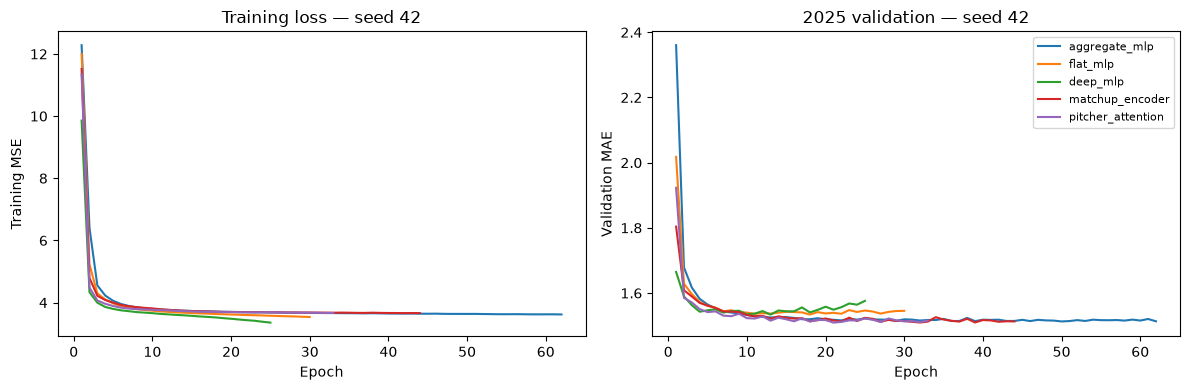

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curves = pd.DataFrame(learning_curves)
for name, group in curves.groupby("architecture", sort=False):
    # Show seed 42 to avoid averaging curves with different stopping lengths.
    curve = group[group["seed"] == SEEDS[0]]
    axes[0].plot(curve["epoch"], curve["train_mse"], label=name)
    axes[1].plot(curve["epoch"], curve["validation_mae"], label=name)
axes[0].set(xlabel="Epoch", ylabel="Training MSE", title="Training loss — seed 42")
axes[1].set(xlabel="Epoch", ylabel="Validation MAE", title="2025 validation — seed 42")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 6. Reading the architecture results

The evaluation helper calculates MAE and RMSE separately for each output, and the notebook
adds R². MAE measures the typical absolute count error; RMSE gives larger errors more
influence. Lower values are better for both. Higher R² indicates better squared-error
performance relative to predicting the evaluation partition's mean.

The default tables and charts summarize 2025 validation, which also supplies stopping and
selection scores. The training-mean and pitcher season-average predictions provide simple
reference errors alongside the neural models. If final-test evaluation is enabled later,
2026 is scored separately after the same 2025-based selection.

Validation


,model,target,mae,rmse,r2
0,aggregate_mlp,Hits allowed,1.7089,2.1285,0.0819
1,aggregate_mlp,Strikeouts,1.7605,2.2253,0.1886
2,aggregate_mlp,Walks,1.0141,1.2582,0.0469
3,aggregate_mlp,Earned runs,1.5564,1.9506,0.0337
8,flat_mlp,Hits allowed,1.7382,2.1658,0.0494
9,flat_mlp,Strikeouts,1.7793,2.2422,0.1762
10,flat_mlp,Walks,1.0233,1.2622,0.0409
11,flat_mlp,Earned runs,1.5682,1.9586,0.0258
16,deep_mlp,Hits allowed,1.7439,2.1671,0.0482
17,deep_mlp,Strikeouts,1.7804,2.2403,0.1777


Test


,model,target,mae,rmse,r2
4,aggregate_mlp,Hits allowed,1.6986,2.1269,0.1337
5,aggregate_mlp,Strikeouts,1.7341,2.1858,0.2297
6,aggregate_mlp,Walks,1.0003,1.2623,0.0708
7,aggregate_mlp,Earned runs,1.5551,1.9532,0.0372
12,flat_mlp,Hits allowed,1.7173,2.1471,0.1172
13,flat_mlp,Strikeouts,1.7613,2.2155,0.2086
14,flat_mlp,Walks,1.0133,1.2695,0.0603
15,flat_mlp,Earned runs,1.5584,1.9544,0.0360
20,deep_mlp,Hits allowed,1.7227,2.1547,0.1109
21,deep_mlp,Strikeouts,1.7696,2.2181,0.2068


model,aggregate_mlp,deep_mlp,flat_mlp,matchup_encoder,pitcher_attention,pitcher_season_average,train_mean
target,,,,,,,
Earned runs,1.5551,1.5650,1.5584,1.5503,1.5473,1.6551,1.6272
Hits allowed,1.6986,1.7227,1.7173,1.6864,1.6919,1.8259,1.8356
Strikeouts,1.7341,1.7696,1.7613,1.7327,1.7360,1.8745,2.0129
Walks,1.0003,1.0169,1.0133,1.0041,1.0066,1.0682,1.0591


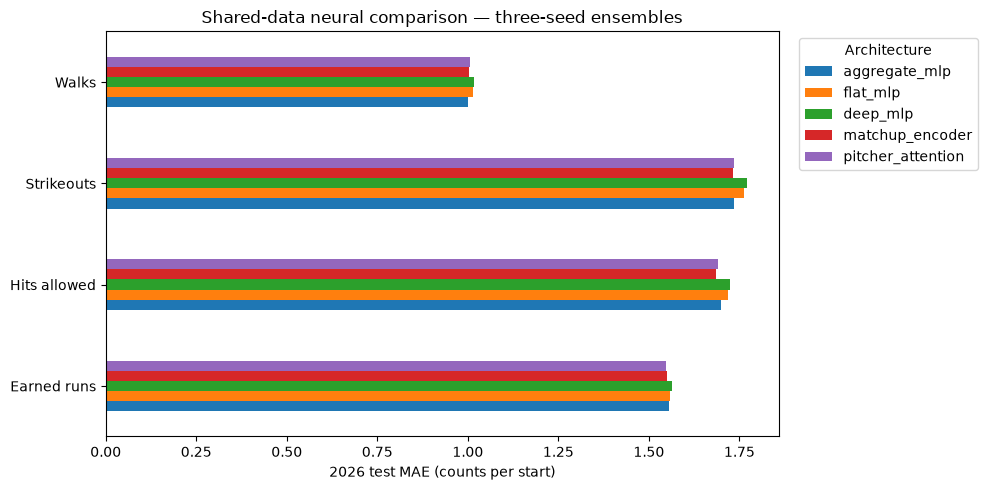

In [12]:
def metrics(y, pred):
    table = evaluate(y, pred, targets=TARGETS).rename(
        columns={"MAE": "mae", "RMSE": "rmse"}
    )
    table["r2"] = [r2_score(y[:, i], pred[:, i]) for i in range(len(TARGETS))]
    return table.to_dict(orient="index")


evaluation_splits = [split for split in frames if split != "train"]
preds = {
    name: {
        split: (
            validation_predictions[name]
            if split == "validation"
            else np.mean(
                [model_predict(model, inputs[split]) for model in fitted], axis=0
            )
        )
        for split in evaluation_splits
    }
    for name, fitted in models.items()
}
preds["train_mean"] = {
    split: np.tile(Y["train"].mean(axis=0), (len(Y[split]), 1))
    for split in evaluation_splits
}
preds["pitcher_season_average"] = {
    split: frames[split][["p_std_h", "p_std_k", "p_std_bb", "p_std_er"]].to_numpy(float)
    for split in evaluation_splits
}
metric_table = pd.DataFrame(
    [
        {"split": split, "model": name, "target": LABELS[target], **values}
        for name, splits in preds.items()
        for split, prediction in splits.items()
        for target, values in metrics(Y[split], prediction).items()
    ]
)
for split in evaluation_splits:
    print(split.title())
    display(metric_table[metric_table["split"] == split].drop(columns="split").round(4))

report_split = "test" if RUN_FINAL_TEST else "validation"
report_year = team_data.TEST_SEASON if RUN_FINAL_TEST else team_data.VAL_SEASON
report_mae = metric_table[metric_table["split"] == report_split].pivot(
    index="target", columns="model", values="mae"
)
display(report_mae.round(4))
ax = report_mae[ARCHITECTURES].plot.barh(figsize=(10, 5))
ax.set(
    xlabel=f"{report_year} {report_split} MAE (counts per start)",
    ylabel="",
    title="Shared-data neural comparison — three-seed ensembles",
)
ax.legend(title="Architecture", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Variation across seeds and paired comparisons

The seed table reports how the errors change across independently initialized fits. The
ensembles average those fits, so their errors can differ from the average error of an
individual seed. The following bootstrap comparisons resample entire dates and preserve the
pairing between predictions on each observation. Negative error differences favor the first
architecture in a comparison.

These intervals describe variation in the reused validation data. They do not account fully
for repeated-player dependence or multiple comparisons, and validation-based model selection
also uses these observations.

In [13]:
seed_metrics = []
for name, fitted in models.items():
    for seed, model in zip(SEEDS, fitted):
        for target, values in metrics(
            Y[report_split], model_predict(model, inputs[report_split])
        ).items():
            seed_metrics.append(
                {"architecture": name, "seed": seed, "target": LABELS[target], **values}
            )
seed_table = pd.DataFrame(seed_metrics)
display(
    seed_table.groupby(["architecture", "target"])["mae"].agg(["mean", "std"]).round(4)
)

comparisons = [
    (name, "aggregate_mlp") for name in ARCHITECTURES if name != "aggregate_mlp"
]
comparisons += [(name, "flat_mlp") for name in ["matchup_encoder", "pitcher_attention"]]
rng = np.random.default_rng(SEED)
intervals = []
for name, reference in comparisons:
    difference = abs(preds[name][report_split] - Y[report_split]) - abs(
        preds[reference][report_split] - Y[report_split]
    )
    daily = pd.DataFrame(difference, columns=TARGETS).assign(
        date=frames[report_split]["date"].to_numpy()
    )
    sums = daily.groupby("date")[TARGETS].sum().to_numpy()
    sizes = daily.groupby("date").size().to_numpy()
    sampled = rng.integers(0, len(sizes), size=(2000, len(sizes)))
    bootstrap = sums[sampled].sum(axis=1) / sizes[sampled].sum(axis=1)[:, None]
    for i, target in enumerate(TARGETS):
        low, high = np.quantile(bootstrap[:, i], [0.025, 0.975])
        intervals.append(
            {
                "architecture": name,
                "reference": reference,
                "target": LABELS[target],
                "MAE difference": difference[:, i].mean(),
                "95% low": low,
                "95% high": high,
            }
        )
interval_table = pd.DataFrame(intervals)
display(interval_table.round(4))


mean     std
architecture      target                      
aggregate_mlp     Earned runs   1.5570  0.0011
                  Hits allowed  1.7029  0.0039
                  Strikeouts    1.7397  0.0010
                  Walks         1.0021  0.0014
deep_mlp          Earned runs   1.5674  0.0051
                  Hits allowed  1.7324  0.0018
                  Strikeouts    1.7804  0.0048
                  Walks         1.0195  0.0041
flat_mlp          Earned runs   1.5628  0.0071
                  Hits allowed  1.7292  0.0082
                  Strikeouts    1.7733  0.0020
                  Walks         1.0170  0.0008
matchup_encoder   Earned runs   1.5513  0.0039
                  Hits allowed  1.6900  0.0015
                  Strikeouts    1.7360  0.0025
                  Walks         1.0054  0.0014
pitcher_attention Earned runs   1.5491  0.0043
                  Hits allowed  1.6968  0.0055
                  Strikeouts    1.7405  0.0068
                  Walks         1.0086  0.0048

,architecture,reference,target,MAE difference,95% low,95% high
0,flat_mlp,aggregate_mlp,Hits allowed,0.0188,0.0063,0.0319
1,flat_mlp,aggregate_mlp,Strikeouts,0.0271,0.0144,0.0392
2,flat_mlp,aggregate_mlp,Walks,0.0130,0.0086,0.0177
3,flat_mlp,aggregate_mlp,Earned runs,0.0033,-0.0034,0.0101
4,deep_mlp,aggregate_mlp,Hits allowed,0.0242,0.0112,0.0365
5,deep_mlp,aggregate_mlp,Strikeouts,0.0354,0.0216,0.0487
6,deep_mlp,aggregate_mlp,Walks,0.0166,0.0112,0.0215
7,deep_mlp,aggregate_mlp,Earned runs,0.0098,0.0028,0.0166
8,matchup_encoder,aggregate_mlp,Hits allowed,-0.0122,-0.0182,-0.0060
9,matchup_encoder,aggregate_mlp,Strikeouts,-0.0014,-0.0072,0.0044


## 7. Saving the main experiment

The main model states are written to `artifacts/neural_shared/`, while metrics, training
curves and the BvP sweep are written to `reports/neural_shared/`. The preprocessing file
records feature order, scaler statistics, the selected BvP strength and its training-derived
mean. The dataset fingerprint identifies the source file used by this run.

These weights were fitted on 2021–2024 outcomes and selected using 2025 outcomes. A saved
prediction for a 2025 row therefore remains a validation prediction even after the model is
reloaded. The saved BvP settings also define the transformation used during inference.

In [14]:
train = frames["train"]
bvp_prior = float(train.lu_bvp_h.sum() / train.lu_bvp_ab.sum())
data_fingerprint = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
bundle = {
    "scalers": scalers,
    "pitcher_columns": pitcher_columns,
    "batter_columns": batter_columns,
    "targets": TARGETS,
    "selected_architecture": selected_name,
    "trained_through": train.date.max().strftime("%Y-%m-%d"),
    "selected_through": frames["validation"].date.max().strftime("%Y-%m-%d"),
    "bvp_prior": bvp_prior,
    "bvp_shrink": BVP_SHRINK,
    "source": str(DATA_PATH.relative_to(ROOT)),
    "source_sha256": data_fingerprint,
}
joblib.dump(bundle, ARTIFACT_DIR / "preprocessing.joblib")
torch.save(
    {name: [model.state_dict() for model in fitted] for name, fitted in models.items()},
    ARTIFACT_DIR / "neural_models.pt",
)
result = {
    "source": bundle["source"],
    "source_sha256": data_fingerprint,
    "split": split_summary.to_dict(orient="index"),
    "final_test_evaluated": RUN_FINAL_TEST,
    "same_day_corrections": same_day_corrections,
    "bvp_prior": bvp_prior,
    "bvp_shrink": BVP_SHRINK,
    "bvp_sweep": sweep_table.to_dict(orient="records"),
    "selected_architecture": selected_name,
    "validation_ensemble_mae": validation_scores,
    "parameter_counts": parameter_counts,
    "training": {
        "seeds": SEEDS,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "loss": "MSE",
        "torch_version": str(torch.__version__),
    },
    "runs": run_summary,
    "metrics": metric_table.to_dict(orient="records"),
}
(REPORT_DIR / "metrics.json").write_text(json.dumps(result, indent=2))
metric_table.to_csv(REPORT_DIR / "metrics.csv", index=False)
seed_table.to_csv(REPORT_DIR / "seed_metrics.csv", index=False)
interval_table.to_csv(REPORT_DIR / "paired_intervals.csv", index=False)
pd.DataFrame(learning_curves).to_csv(REPORT_DIR / "learning_curves.csv", index=False)
for split in evaluation_splits:
    predictions = frames[split][["game_pk", "date", "pitcher_id"] + TARGETS].copy()
    for name, split_preds in preds.items():
        for i, target in enumerate(TARGETS):
            predictions[f"{name}_{target}"] = split_preds[split][:, i]
    predictions.to_csv(ARTIFACT_DIR / f"{split}_predictions.csv", index=False)
print("Saved shared-data checkpoints, metrics and predictions.")

sweep_table.to_csv(REPORT_DIR / "bvp_sweep.csv", index=False)
pd.DataFrame(sweep_runs).to_csv(REPORT_DIR / "bvp_sweep_runs.csv", index=False)


Saved shared-data checkpoints, metrics and predictions.


## 8. Reloading the model for feature-row inference

Inference begins with a row containing the same historical features as the shared table,
including historical BvP hits and at-bats. The saved smoothing strength is applied to those
counts, the saved scalers transform the inputs, and the selected architecture's three
reloaded models generate predictions that are averaged.

The example below uses a validation row and checks that reloaded predictions match the
in-memory ensemble. Replacing its outcome columns does not change the prediction because
those columns are outside the feature selection. A new game likewise needs a pregame feature
row; the model cannot construct its historical summaries from player IDs alone.

In [15]:
def predict_rows(rows):
    bundle = joblib.load(ARTIFACT_DIR / "preprocessing.joblib")
    if pd.to_datetime(rows["date"]).le(pd.Timestamp(bundle["trained_through"])).any():
        raise ValueError("Inference rows must be after the weights' training cutoff")
    rows = apply_bvp_smoothing(rows, bundle["bvp_prior"], bundle["bvp_shrink"])
    values = transform_inputs(
        rows, bundle["scalers"], bundle["pitcher_columns"], bundle["batter_columns"]
    )
    states = torch.load(
        ARTIFACT_DIR / "neural_models.pt", map_location="cpu", weights_only=True
    )
    predictions = []
    for state in states[bundle["selected_architecture"]]:
        model = make_model(bundle["selected_architecture"])
        model.load_state_dict(state)
        predictions.append(model_predict(model, values))
    return pd.DataFrame(
        np.mean(predictions, axis=0), columns=bundle["targets"], index=rows.index
    )


example = frames["validation"].head(1).copy()
prediction = predict_rows(example)
expected = preds[selected_name]["validation"][:1]
assert np.allclose(prediction.to_numpy(), expected, atol=1e-5)
changed_labels = example.copy()
changed_labels[TARGETS] = 999
assert np.allclose(
    predict_rows(changed_labels).to_numpy(), prediction.to_numpy(), atol=1e-5
)
display(prediction.rename(columns=LABELS).T.rename(columns={0: "Predicted count"}))
print("Saved-model predictions match; changing target columns cannot affect inference.")

original_example = source_frames["validation"].head(1).copy()
assert np.allclose(
    predict_rows(original_example).to_numpy(), prediction.to_numpy(), atol=1e-5
)
print("Inference reapplies saved BvP strength to raw historical counts.")


,Predicted count
Hits allowed,4.275808
Strikeouts,5.125711
Walks,1.200046
Earned runs,1.856826


Saved-model predictions match; changing target columns cannot affect inference.


Inference reapplies saved BvP strength to raw historical counts.


## 9. The initial comparison in context

The initial results distinguish input organization from model capacity. The flat model keeps
individual batter statistics, the deeper model adds layers, and the shared encoders apply a
common transformation to individual pitcher–batter pairs. In the saved run, attention has
the lowest average validation MAE. Its gains over the aggregate MLP are modest, and extra
depth alone does not improve that score.

BvP strength is selected alongside architecture, so these results reflect both choices.
They are also based on a different feature table and split from the earlier JSON-based
experiment. The following sections retain this shared-data setup and examine training
objectives, additional history and feature-group removals in more detail.

In [16]:
print("Selected on 2025 validation:", selected_name)
display(
    metric_table[
        (metric_table["split"] == "validation")
        & (metric_table["model"] == selected_name)
    ][["target", "mae", "rmse", "r2"]].round(4)
)
for name in ["flat_mlp", "matchup_encoder", "pitcher_attention"]:
    change = report_mae[name] - report_mae["aggregate_mlp"]
    print(
        f"{name}: lower {report_year} {report_split} MAE than aggregation on {(change < 0).sum()}/4 targets."
    )
print("2026 final test evaluated:", RUN_FINAL_TEST)

print("Selected BvP pseudo-at-bats:", BVP_SHRINK)


Selected on 2025 validation: pitcher_attention


,target,mae,rmse,r2
32,Hits allowed,1.7018,2.1295,0.0810
33,Strikeouts,1.7546,2.2146,0.1964
34,Walks,1.0159,1.2614,0.0422
35,Earned runs,1.5559,1.9548,0.0296


flat_mlp: lower 2026 test MAE than aggregation on 0/4 targets.
matchup_encoder: lower 2026 test MAE than aggregation on 3/4 targets.
pitcher_attention: lower 2026 test MAE than aggregation on 2/4 targets.
2026 final test evaluated: True
Selected BvP pseudo-at-bats: 100


## 10. Changes to training, features and model capacity

The study below starts from a fresh pitcher-attention reference using the selected BvP
strength. It compares MSE, MAE and Huber objectives, target-loss weighting, separate output
heads, additional history, hidden widths and regularization. Most variants change a single
component; the combined-history variant adds both recent-form and workload features.

The study uses 2021–2024 training and 2025 validation throughout. Its checkpoints and reports
are separate from the main architecture comparison. Three seeds and the same stopping budget
are used for each configuration, and exact duplicate reference fits are reused within the
kernel. Re-executing the runner-definition cell clears that cache. No 2026 observations
are passed to this study runner.

In [17]:
from dataclasses import asdict, dataclass, replace
import time

RUN_IMPROVEMENT_STUDY = False
RUN_DEEP_ABLATIONS = False
STUDY_SEEDS = list(SEEDS)
STUDY_DIR = ROOT / "reports" / "neural_experiments"
STUDY_ARTIFACTS = ROOT / "artifacts" / "neural_experiments"
for folder in [STUDY_DIR, STUDY_ARTIFACTS]:
    folder.mkdir(parents=True, exist_ok=True)


@dataclass(frozen=True)
class StudyConfig:
    name: str
    architecture: str = "pitcher_attention"
    loss: str = "mse"
    balance_targets: bool = False
    separate_heads: bool = False
    extra_features: str = "none"
    width: int = 32
    dropout: float = 0.0
    learning_rate: float = LEARNING_RATE
    weight_decay: float = WEIGHT_DECAY
    feature_set: str = "full"


REFERENCE = StudyConfig("reference")
IMPROVEMENTS = [
    REFERENCE,
    replace(REFERENCE, name="loss_mae", loss="mae"),
    replace(REFERENCE, name="loss_huber", loss="huber"),
    replace(REFERENCE, name="balanced_mse", balance_targets=True),
    replace(REFERENCE, name="separate_heads", separate_heads=True),
    replace(REFERENCE, name="recent_form", extra_features="recent"),
    replace(REFERENCE, name="workload_history", extra_features="workload"),
    replace(REFERENCE, name="recent_and_workload", extra_features="both"),
    replace(REFERENCE, name="width_16", width=16),
    replace(REFERENCE, name="width_64", width=64),
    replace(REFERENCE, name="dropout_0.1", dropout=0.1),
    replace(REFERENCE, name="weight_decay_0.01", weight_decay=0.01),
    replace(REFERENCE, name="learning_rate_0.0003", learning_rate=0.0003),
]
ABLATION_ARCHITECTURES = ["deep_mlp", "matchup_encoder", "pitcher_attention"]
ABLATION_SETS = [
    "full",
    "pitcher_only",
    "lineup_only",
    "no_bvp",
    "no_platoon",
    "no_recent_form",
    "no_workload",
]
print("Improvement fits:", len(IMPROVEMENTS) * len(STUDY_SEEDS))
print(
    "Ablation fits before reference reuse:",
    len(ABLATION_ARCHITECTURES) * len(ABLATION_SETS) * len(STUDY_SEEDS),
)


Improvement fits: 39
Ablation fits before reference reuse: 63


### Additional recent-form and workload histories

The next cell reads the team's cached raw starter logs and constructs 18 additional pitcher
features. Outcome summaries include three-start averages, ten-start averages and exponentially
weighted averages. Workload summaries include three-start and exponentially weighted pitch
counts, outs and batters faced. Exponential weights have a half-life of five prior starts.

For each game row, a backward date join retrieves the latest summary strictly before that
date. Current-day outcomes are excluded even when there are multiple starts on the same
date. Missing histories use fallback values fitted from the training partition. These
features extend the existing last-five and longer-term summaries without changing the
shared CSV or using the current game's workload.

In [18]:
def additional_history(query_frames, raw=None):
    years = sorted(
        set(pd.concat([f["season"] for f in query_frames.values()]).astype(int))
    )
    if raw is None:
        paths = [ROOT / "data" / "raw" / f"starts_{year}.csv.gz" for year in years]
        missing = [str(path) for path in paths if not path.is_file()]
        if missing:
            raise FileNotFoundError(
                f"Recent/workload experiments need cached raw starter logs: {missing}"
            )
        raw = pd.concat(
            [pd.read_csv(path, parse_dates=["date"]) for path in paths],
            ignore_index=True,
        )
    else:
        raw = raw.copy()
        raw["date"] = pd.to_datetime(raw["date"])
    rows = []
    outcome_columns = ["h", "k", "bb", "er"]
    workload_columns = ["outs", "pitches", "bf"]
    columns = outcome_columns + workload_columns
    for pitcher_id, group in raw.groupby("pitcher_id", sort=False):
        history = []
        for date, daily in group.sort_values(["date", "game_pk"]).groupby(
            "date", sort=True
        ):
            history.extend(daily[columns].to_numpy(float))
            values = np.asarray(history)
            weights = np.exp2(-np.arange(len(values) - 1, -1, -1) / 5)
            ewma = np.average(values, axis=0, weights=weights)
            row = {"pitcher_id": pitcher_id, "date": date}
            for j, column in enumerate(columns):
                prefix = "extra_form" if column in outcome_columns else "extra_work"
                row[f"{prefix}_ewma_{column}"] = ewma[j]
                row[f"{prefix}_last3_{column}"] = values[-3:, j].mean()
                if column in outcome_columns:
                    row[f"{prefix}_last10_{column}"] = values[-10:, j].mean()
            rows.append(row)
    history = pd.DataFrame(rows).sort_values("date")
    extra_columns = [c for c in history if c.startswith("extra_")]
    joined = {}
    for split, frame in query_frames.items():
        left = frame[["pitcher_id", "date"]].copy().assign(_row=np.arange(len(frame)))
        merged = pd.merge_asof(
            left.sort_values("date"),
            history,
            on="date",
            by="pitcher_id",
            direction="backward",
            allow_exact_matches=False,
        )
        joined[split] = merged.sort_values("_row")[extra_columns].reset_index(drop=True)
    fallback = joined["train"].mean().fillna(0)
    return {split: values.fillna(fallback) for split, values in joined.items()}


study_frames = {split: frames[split].copy() for split in ["train", "validation"]}
assert not any(frame.season.eq(2026).any() for frame in study_frames.values())
extra_history = additional_history(study_frames)
for split, frame in study_frames.items():
    frame[extra_history[split].columns] = extra_history[split].to_numpy()
print("Added history features:", len(extra_history["train"].columns))


Added history features: 18


### Shared network definitions and feature masks

The parameterized network exposes width, dropout and the form of the output head while
retaining the same pitcher–lineup computation. The deep-MLP reference also retains the
original network's activation placement. Separate target heads add their own hidden layers,
so their parameter count increases and is reported in the result table.

A feature ablation instead keeps the network dimensions fixed. Selected standardized input
channels are set to zero in both training and validation, and a new model is fitted from
scratch. Pitcher-only removes all batter statistics and positional coordinates but keeps
home context. Lineup-only removes pitcher history and hand while also keeping home context.
The remaining masks remove narrower feature groups. These fits measure the contribution of
available information under the same capacity and optimization settings.

In [19]:
def study_inputs(config):
    columns = list(pitcher_columns)
    if config.extra_features != "none":
        prefixes = {
            "recent": ("extra_form_",),
            "workload": ("extra_work_",),
            "both": ("extra_form_", "extra_work_"),
        }[config.extra_features]
        columns += [c for c in study_frames["train"] if c.startswith(prefixes)]
    p_train, b_train = raw_inputs(study_frames["train"], columns, batter_columns)
    fitted = {
        "pitcher": StandardScaler().fit(p_train),
        "batter": StandardScaler().fit(b_train.reshape(-1, BATTER_DIM)),
    }
    values = {
        split: transform_inputs(frame, fitted, columns, batter_columns)
        for split, frame in study_frames.items()
    }
    p_mask = torch.ones(len(columns))
    b_mask = torch.ones(BATTER_DIM)
    if config.feature_set == "pitcher_only":
        b_mask[:] = 0
    elif config.feature_set == "lineup_only":
        p_mask = torch.tensor([float(c == "home") for c in columns])
    elif config.feature_set == "no_bvp":
        b_mask = torch.tensor([float("bvp" not in c) for c in batter_columns[0]])
    elif config.feature_set == "no_platoon":
        p_mask = torch.tensor([float(c != "p_throws_R") for c in columns])
        b_mask = torch.tensor(
            [
                float(not c.endswith(("_platoon_adv", "_bats_L")))
                for c in batter_columns[0]
            ]
        )
    elif config.feature_set == "no_recent_form":
        p_mask = torch.tensor(
            [
                float(
                    c not in ["p_l5_h", "p_l5_k", "p_l5_bb", "p_l5_er"]
                    and not c.startswith("extra_form_")
                )
                for c in columns
            ]
        )
    elif config.feature_set == "no_workload":
        p_mask = torch.tensor(
            [
                float(
                    c not in ["p_l5_outs", "p_l5_pitches", "p_outs_per_start"]
                    and not c.startswith("extra_work_")
                )
                for c in columns
            ]
        )
    elif config.feature_set != "full":
        raise ValueError(config.feature_set)
    return (
        {split: (p * p_mask, b * b_mask) for split, (p, b) in values.items()},
        fitted,
        columns,
        p_mask,
        b_mask,
    )


class StudyNetwork(nn.Module):
    def __init__(self, config, pitcher_dim):
        super().__init__()
        self.config = config
        width = config.width
        self.register_buffer("slots", torch.linspace(-1, 1, 9).reshape(1, 9, 1))
        if config.architecture == "deep_mlp":
            self.flat_encoder = dense_layers(
                pitcher_dim + 9 * BATTER_DIM, [4 * width, 2 * width], width
            )
            head_dim = width
        else:
            self.pitcher_encoder = dense_layers(pitcher_dim, [width], width)
            self.matchup_encoder = dense_layers(width + BATTER_DIM + 1, [width], width)
            self.attention = (
                nn.MultiheadAttention(width, 4, batch_first=True)
                if config.architecture == "pitcher_attention"
                else None
            )
            head_dim = 2 * width
        self.dropout = nn.Dropout(config.dropout)
        if config.separate_heads:
            self.heads = nn.ModuleList(
                [dense_layers(head_dim, [max(8, width // 2)], 1) for _ in TARGETS]
            )
        else:
            self.head = dense_layers(
                head_dim, [width] if config.architecture != "deep_mlp" else [], 4
            )

    def forward(self, pitcher, batters):
        if self.config.architecture == "deep_mlp":
            state = nn.functional.relu(
                self.flat_encoder(torch.cat([pitcher, batters.flatten(1)], dim=-1))
            )
        else:
            p = self.pitcher_encoder(pitcher)
            slot = self.slots.expand(len(p), -1, -1)
            if self.config.feature_set == "pitcher_only":
                slot = slot * 0
            pairs = self.matchup_encoder(
                torch.cat([p[:, None, :].expand(-1, 9, -1), batters, slot], dim=-1)
            )
            if self.attention is None:
                lineup = pairs.mean(dim=1)
            else:
                lineup, _ = self.attention(
                    p[:, None, :], pairs, pairs, need_weights=False
                )
                lineup = lineup[:, 0, :]
            state = torch.cat([p, lineup], dim=-1)
        state = self.dropout(state)
        output = (
            torch.cat([head(state) for head in self.heads], dim=-1)
            if self.config.separate_heads
            else self.head(state)
        )
        return nn.functional.softplus(output)


def study_loss(prediction, target, config, target_weights):
    if config.loss == "mse":
        errors = (prediction - target).square()
    elif config.loss == "mae":
        errors = (prediction - target).abs()
    elif config.loss == "huber":
        errors = nn.functional.huber_loss(
            prediction, target, reduction="none", delta=1.0
        )
    else:
        raise ValueError(config.loss)
    return (errors * target_weights).mean()


### The common training loop

Every configuration passes through the same runner. It initializes each seed, shuffles only
training observations, updates weights with AdamW, and checks raw-count validation MAE after
each epoch. The best validation weights are retained under the shared patience rule.

The training objective changes within this loop. MSE squares each error, MAE uses its
absolute value, and Huber is quadratic near zero and linear for larger errors. Balanced MSE
weights each target by inverse training variance, with weights normalized to mean one.
Stopping and selection continue to use unweighted validation MAE for all variants, keeping
the evaluation scale consistent across different training objectives.

In [20]:
study_targets = {
    split: frame[TARGETS].to_numpy(float) for split, frame in study_frames.items()
}
study_cache = {}


def run_study(config):
    key = (
        tuple((k, v) for k, v in asdict(config).items() if k != "name"),
        tuple(STUDY_SEEDS),
        MAX_EPOCHS,
        PATIENCE,
        BATCH_SIZE,
        BVP_SHRINK,
        data_fingerprint,
    )
    if key in study_cache:
        return study_cache[key]
    values, fitted_scalers, columns, p_mask, b_mask = study_inputs(config)
    target_weights = np.ones(4)
    if config.balance_targets:
        target_weights = 1 / np.maximum(study_targets["train"].var(axis=0), 1e-6)
        target_weights /= target_weights.mean()
    weights = torch.tensor(target_weights, dtype=torch.float32)
    fitted_models, histories, seed_rows = [], [], []
    started = time.perf_counter()
    for seed in STUDY_SEEDS:
        torch.manual_seed(seed)
        model = StudyNetwork(config, len(columns))
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=config.learning_rate,
            weight_decay=config.weight_decay,
        )
        dataset = TensorDataset(
            *values["train"], torch.tensor(study_targets["train"], dtype=torch.float32)
        )
        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            generator=torch.Generator().manual_seed(seed),
        )
        best, best_epoch, stale = float("inf"), 0, 0
        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            total = 0.0
            for pitcher, batters, target in loader:
                optimizer.zero_grad()
                loss = study_loss(model(pitcher, batters), target, config, weights)
                loss.backward()
                optimizer.step()
                total += float(loss.detach()) * len(target)
            prediction = model_predict(model, values["validation"])
            score = float(mean_absolute_error(study_targets["validation"], prediction))
            histories.append(
                {
                    "seed": seed,
                    "epoch": epoch,
                    "train_objective": total / len(dataset),
                    "validation_mae": score,
                }
            )
            if score < best - 1e-4:
                best, best_epoch, stale = score, epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                stale += 1
            if stale >= PATIENCE:
                break
        model.load_state_dict(best_state)
        model.eval()
        fitted_models.append(model)
        train_prediction = model_predict(model, values["train"])
        for target, result in metrics(
            study_targets["validation"], model_predict(model, values["validation"])
        ).items():
            seed_rows.append(
                {
                    "seed": seed,
                    "target": LABELS[target],
                    "best_epoch": best_epoch,
                    "epochs_run": epoch,
                    "train_mae": float(
                        np.abs(
                            train_prediction[:, TARGETS.index(target)]
                            - study_targets["train"][:, TARGETS.index(target)]
                        ).mean()
                    ),
                    **result,
                }
            )
    prediction = np.mean(
        [model_predict(model, values["validation"]) for model in fitted_models], axis=0
    )
    result = {
        "config": config,
        "models": fitted_models,
        "scalers": fitted_scalers,
        "pitcher_columns": columns,
        "p_mask": p_mask,
        "b_mask": b_mask,
        "prediction": prediction,
        "curve": pd.DataFrame(histories),
        "seed_metrics": pd.DataFrame(seed_rows),
        "metrics": metrics(study_targets["validation"], prediction),
        "parameters": sum(p.numel() for p in fitted_models[0].parameters()),
        "seconds": time.perf_counter() - started,
    }
    study_cache[key] = result
    print(
        f"{config.name}: validation MAE {np.abs(prediction - study_targets['validation']).mean():.4f}, {result['parameters']:,} parameters",
        flush=True,
    )
    return result


def result_rows(result, experiment, architecture=None):
    return [
        {
            "experiment": experiment,
            "architecture": architecture or result["config"].architecture,
            "target": LABELS[target],
            "parameters": result["parameters"],
            **values,
        }
        for target, values in result["metrics"].items()
    ]


### Checks on the study implementation

The checks compare masked and unmasked tensors, confirming that removed channels are zero
and retained channels are unchanged. They also check output shape and finiteness across
width and head variants. The deep-MLP reference is compared directly with the original
network under the same initialized weights and inputs.

A synthetic history example then changes current and future outcomes while retaining an
earlier query date. The joined historical features remain unchanged. Together, these checks
cover the study's feature masks, model definitions and earlier-date feature construction.

In [21]:
reference_values, _, reference_columns, _, _ = study_inputs(REFERENCE)
for feature_set in ABLATION_SETS:
    config = replace(REFERENCE, feature_set=feature_set)
    values, _, _, p_mask, b_mask = study_inputs(config)
    assert torch.equal(
        values["validation"][0], reference_values["validation"][0] * p_mask
    )
    assert torch.equal(
        values["validation"][1], reference_values["validation"][1] * b_mask
    )
    if feature_set == "pitcher_only":
        assert torch.count_nonzero(values["train"][1]) == 0
    if feature_set == "no_bvp":
        assert all(
            b_mask[i] == 0 for i, col in enumerate(batter_columns[0]) if "bvp" in col
        )
for config in IMPROVEMENTS:
    values, _, columns, _, _ = study_inputs(config)
    model = StudyNetwork(config, len(columns)).eval()
    prediction = model(values["train"][0][:2], values["train"][1][:2])
    assert (
        prediction.shape == (2, 4)
        and torch.isfinite(prediction).all()
        and (prediction > 0).all()
    )
reference_model = StudyNetwork(REFERENCE, len(reference_columns))
assert (
    sum(p.numel() for p in reference_model.parameters())
    == parameter_counts["pitcher_attention"]
)
assert set(study_frames) == {"train", "validation"}
print("Study architecture, feature-mask and validation-only checks passed.")

# Synthetic current/future outcomes cannot change an earlier-date history query.
q = {
    "train": pd.DataFrame(
        {"season": [2023], "pitcher_id": [1], "date": pd.to_datetime(["2023-04-01"])}
    ),
    "validation": pd.DataFrame(
        {"season": [2024], "pitcher_id": [1], "date": pd.to_datetime(["2024-04-02"])}
    ),
}
fake = pd.DataFrame(
    {
        "pitcher_id": [1, 1, 1],
        "game_pk": [1, 2, 3],
        "date": pd.to_datetime(["2024-04-01", "2024-04-02", "2024-04-03"]),
        **{c: [1.0, 2.0, 3.0] for c in ["h", "k", "bb", "er", "outs", "pitches", "bf"]},
    }
)
before = additional_history(q, raw=fake)["validation"]
fake.loc[1:, ["h", "k", "bb", "er", "outs", "pitches", "bf"]] = 999
after = additional_history(q, raw=fake)["validation"]
assert np.allclose(before, after)
print("Additional-history current/future leakage check passed.")

# The deep ablation reference must exactly match the original network, including activation placement.
torch.manual_seed(777)
original_deep = make_model("deep_mlp").eval()
torch.manual_seed(777)
study_deep = StudyNetwork(replace(REFERENCE, architecture="deep_mlp"), len(pitcher_columns)).eval()
assert torch.allclose(original_deep(inputs["train"][0][:3], inputs["train"][1][:3]), study_deep(inputs["train"][0][:3], inputs["train"][1][:3]), atol=1e-6)
print("Deep ablation reference exactly matches the original network.")


Study architecture, feature-mask and validation-only checks passed.
Additional-history current/future leakage check passed.
Deep ablation reference exactly matches the original network.


### Improvement results and learning curves

The table combines the three seed predictions for each configuration and reports ensemble
MAE, average per-target RMSE, parameter count and fitting time. Seed means and standard
deviations describe initialization variability. The plot places these seed summaries next
to each ensemble score; its error bars are seed standard deviations, not confidence intervals.
The heatmap expresses each target's MAE change relative to the fresh attention reference.

In the saved run, MAE training lowers average validation MAE from 1.5071 to 1.4999. Most of
that reduction comes from walks and earned runs, while average per-target RMSE rises from
1.8901 to 1.9022. Huber gives a smaller MAE reduction, and combining recent-form and workload
history reaches 1.5050 with average RMSE 1.8894. Wider networks, separate heads and the tested
regularization changes do not improve on the reference's overall MAE. The learning curves
below keep validation MAE on the same scale across the different training objectives.

In [22]:
improvement_results, improvement_rows = {}, []
if RUN_IMPROVEMENT_STUDY:
    for config in IMPROVEMENTS:
        result = run_study(config)
        improvement_results[config.name] = result
        improvement_rows.extend(result_rows(result, config.name))
    improvement_table = pd.DataFrame(improvement_rows)
    improvement_summary = improvement_table.groupby("experiment").agg(
        ensemble_mae=("mae", "mean"),
        mean_rmse=("rmse", "mean"),
        parameters=("parameters", "first"),
    )
    for name, result in improvement_results.items():
        seed_means = result["seed_metrics"].groupby("seed").mae.mean()
        improvement_summary.loc[name, "seed_mae_mean"] = seed_means.mean()
        improvement_summary.loc[name, "seed_mae_std"] = seed_means.std()
        improvement_summary.loc[name, "fit_seconds"] = result["seconds"]
    display(improvement_summary.sort_values("ensemble_mae").round(4))
    display(
        improvement_table.pivot(
            index="experiment", columns="target", values="mae"
        ).round(4)
    )


In [23]:
def annotated_heatmap(table, title, ax, center_zero=True):
    values = table.to_numpy(float)
    limit = max(float(np.abs(values).max()), 1e-6)
    image = ax.imshow(
        values,
        cmap="RdBu_r" if center_zero else "viridis",
        aspect="auto",
        vmin=-limit if center_zero else None,
        vmax=limit if center_zero else None,
    )
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=25, ha="right")
    ax.set_yticks(range(len(table)), table.index)
    ax.set_title(title)
    for row in range(len(table)):
        for col in range(len(table.columns)):
            value = values[row, col]
            color = "white" if center_zero and abs(value) > 0.65 * limit else "black"
            ax.text(
                col,
                row,
                f"{value:+.3f}" if center_zero else f"{value:.3f}",
                ha="center",
                va="center",
                color=color,
                fontsize=8,
            )
    return image


if RUN_IMPROVEMENT_STUDY:
    summary = improvement_summary.sort_values("ensemble_mae")
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    positions = np.arange(len(summary))
    axes[0].errorbar(
        summary.seed_mae_mean,
        positions,
        xerr=summary.seed_mae_std,
        fmt="o",
        capsize=3,
        color="#4C78A8",
        label="Individual seeds: mean ± SD",
    )
    axes[0].scatter(
        summary.ensemble_mae,
        positions,
        color="#E45756",
        label="Three-seed ensemble",
        zorder=3,
    )
    axes[0].set_yticks(positions, summary.index)
    axes[0].axvline(
        improvement_summary.loc["reference", "ensemble_mae"],
        color="gray",
        linestyle="--",
        alpha=0.5,
    )
    axes[0].set(xlabel="2025 validation MAE", title="Seeds: mean ± SD; dot: ensemble")
    axes[0].legend()
    pivot = improvement_table.pivot(index="experiment", columns="target", values="mae")
    delta = pivot.subtract(pivot.loc["reference"]).drop(index="reference")
    heat = annotated_heatmap(
        delta, "MAE change from reference (negative helps)", axes[1]
    )
    fig.colorbar(heat, ax=axes[1], label="Change in count error")
    fig.tight_layout()
    fig.savefig(STUDY_DIR / "improvement_comparison.png", dpi=160, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4))
    for name in [
        "reference",
        "loss_mae",
        "loss_huber",
        "balanced_mse",
        "separate_heads",
    ]:
        curve = improvement_results[name]["curve"]
        curve = curve[curve.seed == STUDY_SEEDS[0]]
        ax.plot(curve.epoch, curve.validation_mae, label=name)
    ax.set(
        xlabel="Epoch",
        ylabel="2025 validation MAE",
        title="Loss/head experiments — first fixed seed",
    )
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(STUDY_DIR / "loss_learning_curves.png", dpi=160)
    plt.show()


## 11. The existing baseline feature ablations

Shobit's baseline notebook compares pitcher-only, lineup-only, combined and combined-plus-BvP
feature sets for Ridge, random forest and LightGBM. The saved `ablation_2025.csv` contains
per-target RMSE. Both single-source groups retain home context, and each baseline is tuned
on 2025. The notebook also saves game-cluster bootstrap comparisons for adding lineup and
BvP information, together with tree feature-importance plots.

The saved errors are substantially lower with pitcher-only than with lineup-only inputs.
Adding lineup features to pitcher history reduces RMSE modestly, while aggregate BvP adds
little further improvement. This pattern describes predictive information in these models;
it does not establish a causal ranking of pitcher and batter effects. The deep-model
ablations below use individual batters and fixed settings, so their numerical scores also
reflect a different representation and tuning procedure.

,model,features,hits,strikeouts,walks,earned_runs
0,ridge,pitcher only,2.138,2.266,1.261,1.956
1,ridge,lineup only,2.217,2.429,1.284,1.979
2,ridge,combined,2.133,2.224,1.256,1.952
3,ridge,combined + bvp,2.133,2.225,1.257,1.952
4,random forest,pitcher only,2.132,2.263,1.262,1.956
5,random forest,lineup only,2.216,2.433,1.285,1.979
6,random forest,combined,2.130,2.225,1.257,1.952
7,random forest,combined + bvp,2.126,2.224,1.256,1.951
8,lightgbm,pitcher only,2.132,2.264,1.261,1.955
9,lightgbm,lineup only,2.216,2.430,1.284,1.978


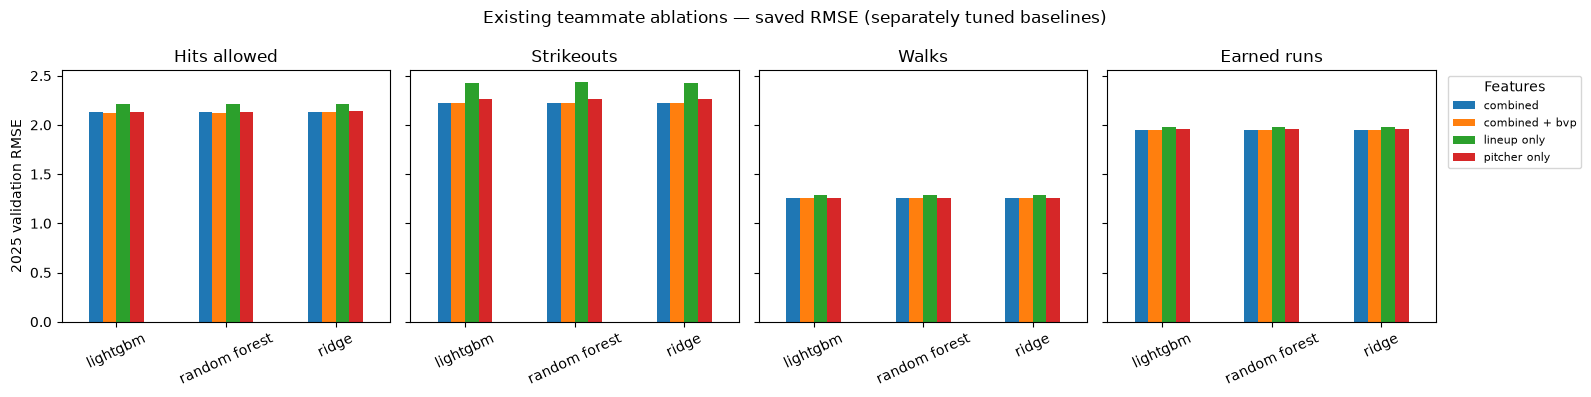

In [24]:
shobit_ablations = pd.read_csv(ROOT / "baselines" / "ablation_2025.csv")
display(shobit_ablations)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, target in zip(axes, TARGETS):
    pivot = shobit_ablations.pivot(index="model", columns="features", values=target)
    pivot.plot.bar(ax=ax, legend=False)
    ax.set(title=LABELS[target], ylabel="2025 validation RMSE", xlabel="")
    ax.tick_params(axis="x", rotation=25)
axes[-1].legend(
    title="Features", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8
)
fig.suptitle("Existing teammate ablations — saved RMSE (separately tuned baselines)")
fig.tight_layout()
fig.savefig(STUDY_DIR / "teammate_ablation_summary.png", dpi=160, bbox_inches="tight")
plt.show()


## 12. Retrained feature ablations in the deep models

Each of the deep MLP, matchup encoder and attention model is fitted with seven input sets:
full features, pitcher-only, lineup-only, and four versions removing BvP, handedness/platoon,
recent-form or workload summaries. The architecture, BvP strength, optimization settings and
three seeds remain fixed within each family. The heatmaps show each reduced model's MAE
minus its own full-feature reference; positive values indicate higher error after removal.

The attention model's full-feature average MAE is 1.5071. Pitcher-only reaches 1.5204 and
lineup-only reaches 1.5856, indicating that both sources add information in this configuration,
with the larger loss following removal of pitcher history. Removing BvP changes its score
to 1.5092, a much smaller difference. BvP removal is nearly neutral for the matchup encoder
and improves the deep MLP, showing that its contribution depends on the architecture.

The narrower masks remove specified columns rather than every indirect trace of a concept.
For example, removing recent outcome lags leaves season and 365-day summaries, and removing
workload summaries leaves rest, start counts and outcome rates. The paired date-bootstrap
table measures variation in these validation differences; it does not turn them into
independent final-test results.

In [25]:
ablation_results, ablation_rows = {}, []
if RUN_DEEP_ABLATIONS:
    for architecture in ABLATION_ARCHITECTURES:
        for feature_set in ABLATION_SETS:
            config = replace(
                REFERENCE,
                name=f"{architecture}/{feature_set}",
                architecture=architecture,
                feature_set=feature_set,
            )
            result = run_study(config)
            ablation_results[(architecture, feature_set)] = result
            ablation_rows.extend(result_rows(result, feature_set, architecture))
    ablation_table = pd.DataFrame(ablation_rows)
    display(
        ablation_table.pivot(
            index=["architecture", "experiment"], columns="target", values="mae"
        ).round(4)
    )

    fig, axes = plt.subplots(
        1, len(ABLATION_ARCHITECTURES), figsize=(17, 5), sharey=True
    )
    for ax, architecture in zip(axes, ABLATION_ARCHITECTURES):
        pivot = ablation_table[ablation_table.architecture == architecture].pivot(
            index="experiment", columns="target", values="mae"
        )
        delta = pivot.subtract(pivot.loc["full"]).drop(index="full")
        image = annotated_heatmap(delta, architecture, ax)
        fig.colorbar(image, ax=ax, label="Δ MAE vs full (positive hurts)")
    fig.suptitle("Retrained deep feature ablations — 2025 validation")
    fig.tight_layout()
    fig.savefig(
        STUDY_DIR / "deep_ablation_comparison.png", dpi=160, bbox_inches="tight"
    )
    plt.show()


In [26]:
if RUN_DEEP_ABLATIONS:
    date_codes, dates = pd.factorize(study_frames["validation"].date)
    sizes = np.bincount(date_codes)
    rng = np.random.default_rng(SEED)
    samples = rng.integers(0, len(dates), size=(1000, len(dates)))
    interval_rows = []
    for architecture in ABLATION_ARCHITECTURES:
        full = ablation_results[(architecture, "full")]["prediction"]
        for feature_set in ABLATION_SETS:
            if feature_set == "full":
                continue
            reduced = ablation_results[(architecture, feature_set)]["prediction"]
            difference = abs(reduced - study_targets["validation"]) - abs(
                full - study_targets["validation"]
            )
            sums = np.stack(
                [
                    np.bincount(
                        date_codes, weights=difference[:, j], minlength=len(dates)
                    )
                    for j in range(4)
                ],
                axis=1,
            )
            bootstrap = sums[samples].sum(axis=1) / sizes[samples].sum(axis=1)[:, None]
            for j, target in enumerate(TARGETS):
                low, high = np.quantile(bootstrap[:, j], [0.025, 0.975])
                interval_rows.append(
                    {
                        "architecture": architecture,
                        "feature_set": feature_set,
                        "target": LABELS[target],
                        "mae_delta_vs_full": difference[:, j].mean(),
                        "95% low": low,
                        "95% high": high,
                    }
                )
    ablation_intervals = pd.DataFrame(interval_rows)
    display(ablation_intervals.round(4))


## 13. Saved study outputs and interpretation

The study writes metrics, seed histories, comparison plots and ablation intervals to
`reports/neural_experiments/`. Its validation predictions and selected exploratory model
are written separately under `artifacts/neural_experiments/`. The checkpoint records the
chosen configuration, while preprocessing records feature order, masks, scalers and BvP
settings. Reloaded-model predictions are checked against the fitted ensemble.

Taken together, the saved results show a small MAE benefit from changing the training loss,
a smaller benefit from additional history, and architecture-dependent contributions from
individual feature groups. MAE training also illustrates a tradeoff: smaller average
absolute errors can accompany larger squared errors. These findings describe model
selection on a repeatedly examined 2025 validation partition. The 2026 final test remains
unscored, and the bootstrap intervals do not adjust for the number of comparisons.

A final frozen configuration can later be evaluated on 2026. Earlier-year validation would
require feature priors to be rebuilt from each fold's training years, because the current
shared table uses training-derived priors through 2024.

In [27]:
if RUN_IMPROVEMENT_STUDY:
    improvement_table.to_csv(STUDY_DIR / "improvement_metrics.csv", index=False)
    improvement_summary.to_csv(STUDY_DIR / "improvement_summary.csv")
    selected_study_name = improvement_summary.ensemble_mae.idxmin()
    selected_study = improvement_results[selected_study_name]
    checkpoint = {
        "config": asdict(selected_study["config"]),
        "states": [m.state_dict() for m in selected_study["models"]],
    }
    torch.save(checkpoint, STUDY_ARTIFACTS / "selected_study_models.pt")
    joblib.dump(
        {
            "scalers": selected_study["scalers"],
            "pitcher_columns": selected_study["pitcher_columns"],
            "batter_columns": batter_columns,
            "p_mask": selected_study["p_mask"].numpy(),
            "b_mask": selected_study["b_mask"].numpy(),
            "bvp_prior": bvp_prior,
            "bvp_shrink": BVP_SHRINK,
            "history_half_life_starts": 5,
        },
        STUDY_ARTIFACTS / "selected_study_preprocessing.joblib",
    )
    # Reload saved states and check inference against the fitted ensemble.
    saved = torch.load(STUDY_ARTIFACTS / "selected_study_models.pt", weights_only=True)
    values, _, columns, _, _ = study_inputs(selected_study["config"])
    reloaded = []
    for state in saved["states"]:
        model = StudyNetwork(StudyConfig(**saved["config"]), len(columns))
        model.load_state_dict(state)
        reloaded.append(model_predict(model, values["validation"]))
    assert np.allclose(
        np.mean(reloaded, axis=0), selected_study["prediction"], atol=1e-5
    )
    print("Best exploratory study configuration:", selected_study_name)
    print(
        "Reference ensemble MAE:", improvement_summary.loc["reference", "ensemble_mae"]
    )
    print(
        "Selected ensemble MAE:",
        improvement_summary.loc[selected_study_name, "ensemble_mae"],
    )
if RUN_DEEP_ABLATIONS:
    ablation_table.to_csv(STUDY_DIR / "deep_ablation_metrics.csv", index=False)
    ablation_intervals.to_csv(STUDY_DIR / "deep_ablation_intervals.csv", index=False)

study_seed_rows, study_curve_rows, prediction_rows = [], [], []
for result in study_cache.values():
    config = asdict(result["config"])
    seed_rows = result["seed_metrics"].assign(
        configuration=config["name"],
        architecture=config["architecture"],
        feature_set=config["feature_set"],
    )
    study_seed_rows.append(seed_rows)
    study_curve_rows.append(result["curve"].assign(configuration=config["name"]))
    prediction_frame = (
        study_frames["validation"][["game_pk", "pitcher_id"]]
        .reset_index(drop=True)
        .copy()
    )
    prediction_frame["configuration"] = config["name"]
    prediction_frame[TARGETS] = result["prediction"]
    prediction_rows.append(prediction_frame)
if study_cache:
    pd.concat(study_seed_rows).to_csv(STUDY_DIR / "seed_metrics.csv", index=False)
    pd.concat(study_curve_rows).to_csv(STUDY_DIR / "learning_curves.csv", index=False)
    pd.concat(prediction_rows, ignore_index=True).to_csv(
        STUDY_ARTIFACTS / "validation_predictions.csv", index=False
    )
    manifest = {
        "data_sha256": data_fingerprint,
        "bvp_shrink": BVP_SHRINK,
        "seeds": STUDY_SEEDS,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "batch_size": BATCH_SIZE,
        "validation_year": 2025,
        "final_test_evaluated": False,
        "configurations": [asdict(r["config"]) for r in study_cache.values()],
    }
    (STUDY_DIR / "experiment_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Study complete; 2026 was not used by the experiment runner.")


Study complete; 2026 was not used by the experiment runner.
